<a href="https://colab.research.google.com/github/halomohammed/Ml-assignment1/blob/main/Adam_Momentum.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import files
uploaded = files.upload()


Saving Position_Salaries.csv.csv to Position_Salaries.csv.csv


In [2]:
import pandas as pd

df = pd.read_csv("Position_Salaries.csv.csv")

df.head()


,Position,Level,Salary
0,Business Analyst,1,45000
1,Junior Consultant,2,50000
2,Senior Consultant,3,60000
3,Manager,4,80000
4,Country Manager,5,110000


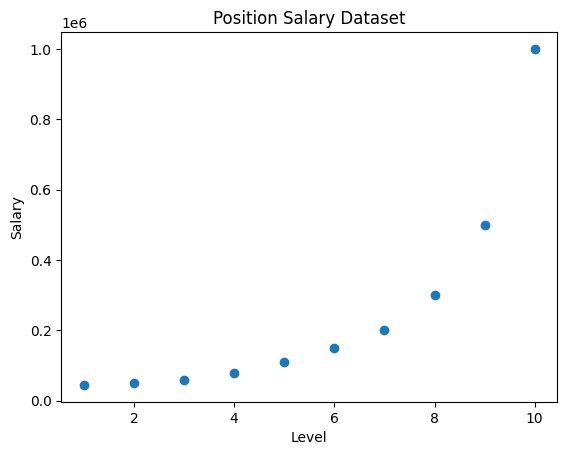

In [3]:
import matplotlib.pyplot as plt

X = df["Level"]
y = df["Salary"]

plt.scatter(X, y)
plt.xlabel("Level")
plt.ylabel("Salary")
plt.title("Position Salary Dataset")
plt.show()


In [4]:
import numpy as np

X = df["Level"].values
y = df["Salary"].values

X_poly = np.column_stack((X, X**2))

X_poly[:5]


array([[ 1,  1],
       [ 2,  4],
       [ 3,  9],
       [ 4, 16],
       [ 5, 25]])

In [5]:
w = np.zeros(2)
b = 0

lr = 0.01
epochs = 500

m_w = np.zeros(2)
m_b = 0

v_w = np.zeros(2)
v_b = 0

beta1 = 0.9
beta2 = 0.999

epsilon = 1e-8

losses = []

n = len(X_poly)

for t in range(1, epochs + 1):

    y_pred = np.dot(X_poly, w) + b

    error = y - y_pred

    dw = (-2/n) * np.dot(X_poly.T, error)
    db = (-2/n) * np.sum(error)

    m_w = beta1 * m_w + (1 - beta1) * dw
    m_b = beta1 * m_b + (1 - beta1) * db

    v_w = beta2 * v_w + (1 - beta2) * (dw ** 2)
    v_b = beta2 * v_b + (1 - beta2) * (db ** 2)

    m_w_hat = m_w / (1 - beta1**t)
    m_b_hat = m_b / (1 - beta1**t)

    v_w_hat = v_w / (1 - beta2**t)
    v_b_hat = v_b / (1 - beta2**t)

    w = w - lr * m_w_hat / (np.sqrt(v_w_hat) + epsilon)
    b = b - lr * m_b_hat / (np.sqrt(v_b_hat) + epsilon)

    loss = np.mean((y - (np.dot(X_poly, w) + b))**2)

    losses.append(loss)


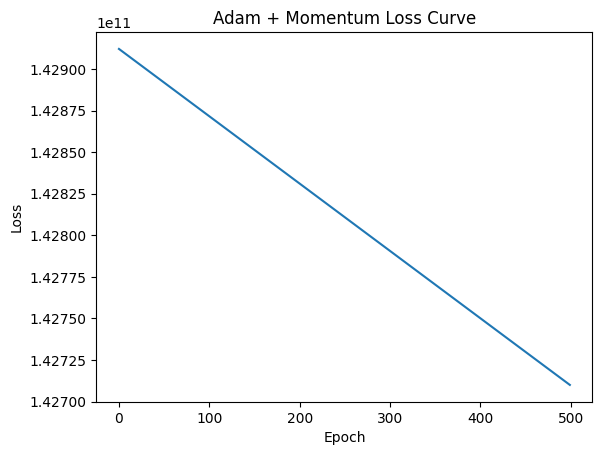

In [6]:
plt.plot(losses)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Adam + Momentum Loss Curve")
plt.show()
